# Table de correspondance : molécules utilisées par groupe de cultures RPG

**Objectif :** associer directement à chacun des **23 `libelle_groupe` du RPG** les **molécules utilisées**
parmi les **10 molécules clés eau** sélectionnées dans [`tf_selection_molecules_eau.ipynb`](tf_selection_molecules_eau.ipynb).

---

## Sources des correspondances (usages agricoles français 2013–2023)

- **Homologations officielles (usages autorisés et retirés sur 2013–2023) :**
  - [Portail officiel E-Phy — ANSES](https://ephy.anses.fr/)
  - [Jeu de données ouvert du catalogue E-Phy — data.gouv.fr](https://www.data.gouv.fr/fr/datasets/donnees-ouvertes-du-catalogue-e-phy-des-produits-phytopharmaceutiques-matieres-fertilisantes-et-supports-de-culture-adjuvants-produits-mixtes-et-melanges/)
- **Nomenclature officielle des 28 groupes de cultures RPG (`CODE_GROUP`) :**
  - [RPG — IGN Géoservices](https://geoservices.ign.fr/rpg) et [jeu de données RPG sur data.gouv.fr](https://www.data.gouv.fr/datasets/rpg)
  - *Précision RPG :* `Autres cultures industrielles` (groupe 24) regroupe betterave sucrière, chicorée, houblon, tabac et PPAM ; `Légumes ou fleurs` (groupe 25) regroupe pomme de terre, légumes de plein champ, maraîchage et horticulture ornementale.
- **Guides techniques des instituts agricoles de filière :**
  - [Arvalis](https://www.arvalis.fr/) *(céréales à paille, maïs, sorgho, pomme de terre)*
  - [Terres Inovia](https://www.terresinovia.fr/) *(colza, tournesol, soja, protéagineux)*
  - [IFV — Institut Français de la Vigne et du Vin](https://www.vignevin.com/) *(viticulture)*
  - [CTIFL](https://www.ctifl.fr/) *(vergers et cultures légumières)*

*(Inclut les usages historiques majeurs de 2013–2023 pour les molécules retirées en cours de période : `isoproturon` en 2017, `imidaclopride` en 2018/2022, `chlorpyriphos-ethyl` en 2020 et `s-metolachlore` en 2023–2024.)*

## 1. Table de correspondance : molécules utilisées par `libelle_groupe`

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Se placer à la racine du dépôt (le notebook est dans notebooks/exploration/)
for _parent in [Path.cwd(), *Path.cwd().parents]:
    if (_parent / "src").is_dir():
        os.chdir(_parent)
        break

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

# Les 10 molécules clés (classées par famille)
MOLECULES_RETENUES = [
    "glyphosate",
    "s-metolachlore",
    "isoproturon",
    "chlorotoluron",
    "cuivre",
    "boscalid",
    "tebuconazole",
    "imidaclopride",
    "cypermethrine",
    "chlorpyriphos-ethyl",
]

FAMILLE_MOLECULE = {
    "glyphosate": "Herbicide",
    "s-metolachlore": "Herbicide",
    "isoproturon": "Herbicide",
    "chlorotoluron": "Herbicide",
    "cuivre": "Fongicide",
    "boscalid": "Fongicide",
    "tebuconazole": "Fongicide",
    "imidaclopride": "Insecticide",
    "cypermethrine": "Insecticide",
    "chlorpyriphos-ethyl": "Insecticide",
}

# Table de correspondance directe : pour chaque libelle_groupe RPG -> molécules utilisées (2013-2023)
MOLECULES_PAR_GROUPE: dict[str, list[str]] = {
    "Blé tendre": [
        "glyphosate", "isoproturon", "chlorotoluron",
        "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Orge": [
        "glyphosate", "isoproturon", "chlorotoluron",
        "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Maïs grain et ensilage": [
        "glyphosate", "s-metolachlore",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Légumes ou fleurs": [
        # Inclut la pomme de terre, le maraîchage et l'horticulture ornementale
        "glyphosate", "s-metolachlore",
        "cuivre", "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Autres céréales": [
        # Blé dur, triticale, seigle, avoine + sorgho (s-metolachlore)
        "glyphosate", "s-metolachlore", "isoproturon", "chlorotoluron",
        "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Divers": [],
    "Prairies permanentes": [],
    "Tournesol": [
        "glyphosate", "s-metolachlore",
        "boscalid",
        "cypermethrine",
    ],
    "Gel (surfaces gelées sans production)": [],
    "Autres cultures industrielles": [
        # Betterave sucrière, chicorée, houblon, tabac, PPAM
        "glyphosate", "s-metolachlore",
        "cuivre", "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Colza": [
        "glyphosate",
        "boscalid", "tebuconazole",
        "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Fourrage": [
        # Luzerne, trèfle, mélanges fourragers (destruction interculture + ravageurs luzerne)
        "glyphosate",
        "chlorpyriphos-ethyl",
    ],
    "Autres oléagineux": [
        # Soja (s-metolachlore), lin oléagineux, moutarde, navette
        "glyphosate", "s-metolachlore",
        "boscalid", "tebuconazole",
        "cypermethrine",
    ],
    "Prairies temporaires": [
        # Destruction / rénovation avant implantation
        "glyphosate",
    ],
    "Protéagineux": [
        # Pois protéagineux, féverole, lupin
        "glyphosate",
        "boscalid", "tebuconazole",
        "cypermethrine",
    ],
    "Estives et landes": [],
    "Vergers": [
        "glyphosate",
        "cuivre", "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Plantes à fibres": [
        # Lin fibres, chanvre
        "glyphosate",
        "tebuconazole",
        "cypermethrine",
    ],
    "Légumineuses à grains": [
        # Lentille, pois chiche, haricots/pois secs
        "glyphosate",
        "boscalid", "tebuconazole",
        "cypermethrine",
    ],
    "Vignes": [
        "glyphosate",
        "cuivre", "boscalid", "tebuconazole",
        "imidaclopride", "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Fruits à coque": [
        # Noyer, noisetier, châtaignier, amandier
        "glyphosate",
        "cuivre",
        "cypermethrine", "chlorpyriphos-ethyl",
    ],
    "Oliviers": [
        "glyphosate",
        "cuivre",
        "cypermethrine",
    ],
    "Riz": [
        # Désherbage interculture avant semis
        "glyphosate",
    ],
}

GROUPES_RPG = list(MOLECULES_PAR_GROUPE.keys())
assert len(GROUPES_RPG) == 23
for grp, mols in MOLECULES_PAR_GROUPE.items():
    assert set(mols) <= set(MOLECULES_RETENUES), f"Molécule inconnue dans {grp}"

# 1. Table principale par groupe : 1 ligne par libelle_groupe -> molécules utilisées
def _filtrer_famille(mols: list[str], fam: str) -> str:
    return ", ".join(m for m in mols if FAMILLE_MOLECULE[m] == fam)

table_par_groupe = (
    pd.DataFrame([
        {
            "libelle_groupe": grp,
            "nb_molecules": len(mols),
            "herbicides": _filtrer_famille(mols, "Herbicide"),
            "fongicides": _filtrer_famille(mols, "Fongicide"),
            "insecticides": _filtrer_famille(mols, "Insecticide"),
            "molecules_utilisees": ", ".join(mols) if mols else "(aucune)",
        }
        for grp, mols in MOLECULES_PAR_GROUPE.items()
    ])
    .sort_values(["nb_molecules", "libelle_groupe"], ascending=[False, True])
    .reset_index(drop=True)
)

# 2. Matrice binaire orientée : 10 molécules (lignes) × 23 groupes RPG (colonnes)
ordre_groupes = table_par_groupe["libelle_groupe"].tolist()
matrice = pd.DataFrame(0, index=MOLECULES_RETENUES, columns=ordre_groupes, dtype="int8")
matrice.index.name = "molecule"
for grp, mols in MOLECULES_PAR_GROUPE.items():
    if mols:
        matrice.loc[mols, grp] = 1

print(f"Groupes RPG couverts par ≥ 1 molécule : {(table_par_groupe['nb_molecules'] > 0).sum()} / {len(GROUPES_RPG)}")
print(f"Total couples actifs (groupe × molécule) : {int(matrice.values.sum())} / {matrice.size}")
display(table_par_groupe)

Groupes RPG couverts par ≥ 1 molécule : 19 / 23
Total couples actifs (groupe × molécule) : 96 / 230


,libelle_groupe,nb_molecules,herbicides,fongicides,insecticides,molecules_utilisees
0,Autres céréales,9,"glyphosate, s-metolachlore, isoproturon, chlorotoluron","boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, s-metolachlore, isoproturon, chlorotoluron, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
1,Autres cultures industrielles,8,"glyphosate, s-metolachlore","cuivre, boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, s-metolachlore, cuivre, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
2,Blé tendre,8,"glyphosate, isoproturon, chlorotoluron","boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, isoproturon, chlorotoluron, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
3,Légumes ou fleurs,8,"glyphosate, s-metolachlore","cuivre, boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, s-metolachlore, cuivre, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
4,Orge,8,"glyphosate, isoproturon, chlorotoluron","boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, isoproturon, chlorotoluron, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
5,Vergers,7,glyphosate,"cuivre, boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, cuivre, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
6,Vignes,7,glyphosate,"cuivre, boscalid, tebuconazole","imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, cuivre, boscalid, tebuconazole, imidaclopride, cypermethrine, chlorpyriphos-ethyl"
7,Autres oléagineux,5,"glyphosate, s-metolachlore","boscalid, tebuconazole",cypermethrine,"glyphosate, s-metolachlore, boscalid, tebuconazole, cypermethrine"
8,Colza,5,glyphosate,"boscalid, tebuconazole","cypermethrine, chlorpyriphos-ethyl","glyphosate, boscalid, tebuconazole, cypermethrine, chlorpyriphos-ethyl"
9,Maïs grain et ensilage,5,"glyphosate, s-metolachlore",,"imidaclopride, cypermethrine, chlorpyriphos-ethyl","glyphosate, s-metolachlore, imidaclopride, cypermethrine, chlorpyriphos-ethyl"


## 2. Vue matricielle (`10 molécules × 23 groupes RPG`)

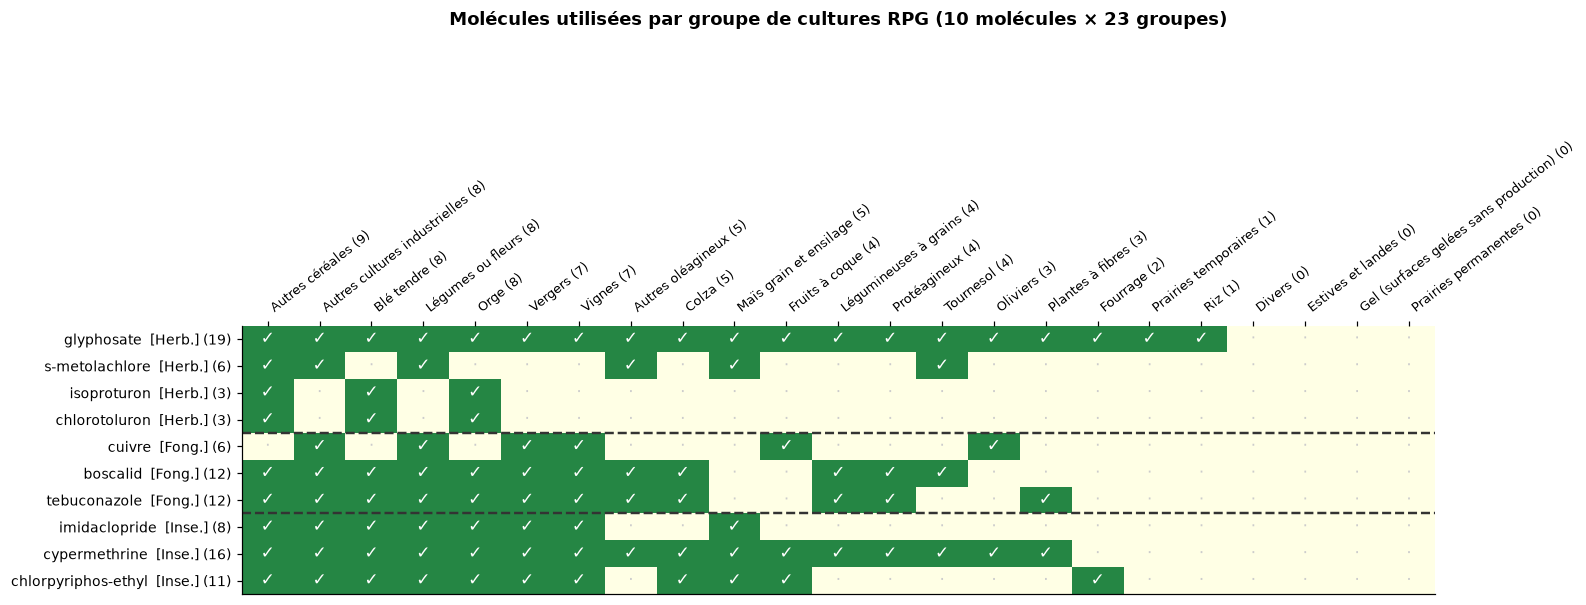

In [2]:
fig, ax = plt.subplots(figsize=(14.5, 5.6))
ax.imshow(matrice.values, cmap="YlGn", vmin=0, vmax=1.35, aspect="auto")

# Séparateurs horizontaux entre Herbicides | Fongicides | Insecticides
for y_sep in [3.5, 6.5]:
    ax.axhline(y_sep, color="#333333", linewidth=1.6, linestyle="--")

etiquettes_y = [f"{mol}  [{FAMILLE_MOLECULE[mol][:4]}.] ({int(matrice.loc[mol].sum())})" for mol in matrice.index]
etiquettes_x = [f"{grp} ({int(matrice[grp].sum())})" for grp in matrice.columns]

ax.set_yticks(range(len(matrice)))
ax.set_yticklabels(etiquettes_y, fontsize=9)
ax.set_xticks(range(len(matrice.columns)))
ax.set_xticklabels(etiquettes_x, fontsize=8.5, rotation=38, ha="left")
ax.xaxis.tick_top()

for i in range(matrice.shape[0]):
    for j in range(matrice.shape[1]):
        if matrice.iloc[i, j] == 1:
            ax.text(j, i, "✓", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
        else:
            ax.text(j, i, "·", ha="center", va="center", color="#cccccc", fontsize=11)

ax.set_title("Molécules utilisées par groupe de cultures RPG (10 molécules × 23 groupes)", pad=75, fontsize=11.5, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Export dans `data/processed/`

- `data/processed/correspondance_groupes_molecules.csv` : **table principale par groupe** (`libelle_groupe`, `nb_molecules`, `herbicides`, `fongicides`, `insecticides`, `molecules_utilisees`).
- `data/processed/matrice_groupes_molecules.csv` : **matrice binaire `10 molécules × 23 groupes`** (`0`/`1`).

In [3]:
dossier = Path("data/processed")
dossier.mkdir(parents=True, exist_ok=True)

chemin_par_groupe = dossier / "correspondance_groupes_molecules.csv"
chemin_matrice = dossier / "matrice_groupes_molecules.csv"

table_par_groupe.to_csv(chemin_par_groupe, index=False, encoding="utf-8-sig")
matrice.to_csv(chemin_matrice, encoding="utf-8-sig")

print(f"Exporté : {chemin_par_groupe} ({len(table_par_groupe)} lignes — 1 par groupe RPG)")
print(f"Exporté : {chemin_matrice} ({matrice.shape[0]} molécules × {matrice.shape[1]} groupes)")

Exporté : data\processed\correspondance_groupes_molecules.csv (23 lignes — 1 par groupe RPG)
Exporté : data\processed\matrice_groupes_molecules.csv (10 molécules × 23 groupes)
